<a href="https://colab.research.google.com/github/hsu01/emotion-detection/blob/experiment-c-noAugmentation/03_resnet18_pretrained.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSE 455 — Facial Expression Recognition (Experiment C: Pretrained ResNet18)

**Course:** CSE 455 Computer Vision, Autumn 2026
**Team:** Hsu Wai Hnin Kyaw, Larrianna Warner, Xuan Nhu Tran, Rina Yuan
**Project:** Facial Expression Recognition Using Deep Learning: Improving Robustness Under Real-World Conditions

## Goal
Build a deep-learning system that classifies a cropped face image into one of seven emotions — **angry, disgust, fear, happy, sad, surprise, neutral** — and returns per-class confidence scores. Then measure how real-world conditions (lighting, rotation, occlusion) degrade it.

## The 2x2 experiment design
| Experiment | Model | Augmentation |
|---|---|---|
| A | CNN trained from scratch | No |
| B | CNN trained from scratch | Yes |
| **C (this notebook)** | Pretrained ResNet18 | No |
| D | Pretrained ResNet18 | Yes |

**This notebook is Experiment C only:** a pretrained ResNet18 model fine-tuned on FER2013, without data augmentation. We use ImageNet pretrained weights as the starting point and replace the final classification layer to predict the seven FER2013 emotion classes. Experiments A, B, and D are implemented in separate notebooks and share the same dataset split and evaluation pipeline for comparison.

## How to run
1. Runtime → Change runtime type → **GPU** (T4).
2. Run cells from top to bottom. The only thing you must supply is your Kaggle credentials (section 1) to download FER2013.
3. The notebook resizes images to 224×224 and applies ImageNet normalization for ResNet18.
4. The best model checkpoint and training history are saved under emotion-detection/checkpoints/experiment_C in your Google Drive.


## 0. Setup

In [8]:
# Install dependencies (torch/torchvision are preinstalled on Colab, but this makes the notebook self-contained).
!pip install -q torch torchvision scikit-learn matplotlib seaborn pandas

In [9]:
import torch

print('PyTorch version:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: no GPU detected — switch to a GPU runtime (Runtime → Change runtime type → T4).')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
Using device: cuda


## 1. Get the data — FER2013 from Kaggle

We use the folder version of FER2013 ([msambare/fer2013](https://www.kaggle.com/datasets/msambare/fer2013)): ~35,887 grayscale 48x48 face images, split into `train/` and `test/` folders, each with 7 emotion subfolders. **The official test set stays untouched until final evaluation** — validation comes from a split of the train set (section 3).

**Kaggle credentials — do one of these before running the next cell:**
- **Option A (recommended):** in Colab, click the key icon in the left sidebar (Secrets) and add two secrets: `KAGGLE_USERNAME` (your Kaggle username) and `KAGGLE_KEY` (your API key).
- **Option B:** go to Kaggle → your profile → Settings → **Create New API Token**. That downloads `kaggle.json`. Upload it with the Files panel in Colab, then run `!cp kaggle.json ~/.kaggle/kaggle.json`.

Never commit `kaggle.json` — it is in the repo's `.gitignore`.

In [12]:
import json
import os

# --- Kaggle credentials (see the markdown cell above) ---
os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)

try:
    from google.colab import userdata
    creds = {'username': userdata.get('KAGGLE_USERNAME'), 'key': userdata.get('KAGGLE_KEY')}
    with open(os.path.expanduser('~/.kaggle/kaggle.json'), 'w') as f:
        json.dump(creds, f)
    print('Kaggle credentials written from Colab Secrets.')
except Exception as e:
    print('Colab Secrets not found — upload kaggle.json and copy it to ~/.kaggle/ :', e)

if not os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json')):
    raise RuntimeError('kaggle.json not found. Add KAGGLE_USERNAME / KAGGLE_KEY as Colab Secrets, '
                       'or upload kaggle.json and run: !cp kaggle.json ~/.kaggle/kaggle.json')
os.chmod(os.path.expanduser('~/.kaggle/kaggle.json'), 0o600)

# --- Download FER2013 (msambare/fer2013) ---
# The zip contains train/ and test/ folders, each with 7 emotion subfolders.
!mkdir -p /content/data
!kaggle datasets download -d msambare/fer2013 -p /content/data --unzip
!ls /content/data
print('Download finished.')

Kaggle credentials written from Colab Secrets.
Dataset URL: https://www.kaggle.com/datasets/msambare/fer2013
License(s): DbCL-1.0
100% 60.3M/60.3M [00:02<00:00, 21.1MB/s]

test  train
Download finished.


In [13]:
from collections import Counter
from pathlib import Path

DATA_ROOT = '/content/data'  # change this if your FER2013 folders landed elsewhere

train_dir = Path(DATA_ROOT) / 'train'
test_dir = Path(DATA_ROOT) / 'test'
assert train_dir.is_dir(), f'train/ not found under {DATA_ROOT} — check DATA_ROOT'
assert test_dir.is_dir(), f'test/ not found under {DATA_ROOT} — check DATA_ROOT'

# Class names in alphabetical order — this is also the label index order
# torchvision.datasets.ImageFolder uses (0=angry, 1=disgust, 2=fear, 3=happy,
# 4=neutral, 5=sad, 6=surprise).
CLASS_NAMES = sorted(d.name for d in train_dir.iterdir() if d.is_dir())
print('Classes:', CLASS_NAMES)

for split, d in [('train', train_dir), ('test', test_dir)]:
    counts = {cls: len([p for p in (d / cls).iterdir() if p.is_file()]) for cls in CLASS_NAMES}
    total = sum(counts.values())
    print(f'\n{split}: {total} images')
    for cls in CLASS_NAMES:
        print(f'  {cls:9s} {counts[cls]:5d}  ({counts[cls] / total:.1%})')

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

train: 28709 images
  angry      3995  (13.9%)
  disgust     436  (1.5%)
  fear       4097  (14.3%)
  happy      7215  (25.1%)
  neutral    4965  (17.3%)
  sad        4830  (16.8%)
  surprise   3171  (11.0%)

test: 7178 images
  angry       958  (13.3%)
  disgust     111  (1.5%)
  fear       1024  (14.3%)
  happy      1774  (24.7%)
  neutral    1233  (17.2%)
  sad        1247  (17.4%)
  surprise    831  (11.6%)


## 2. Explore the data

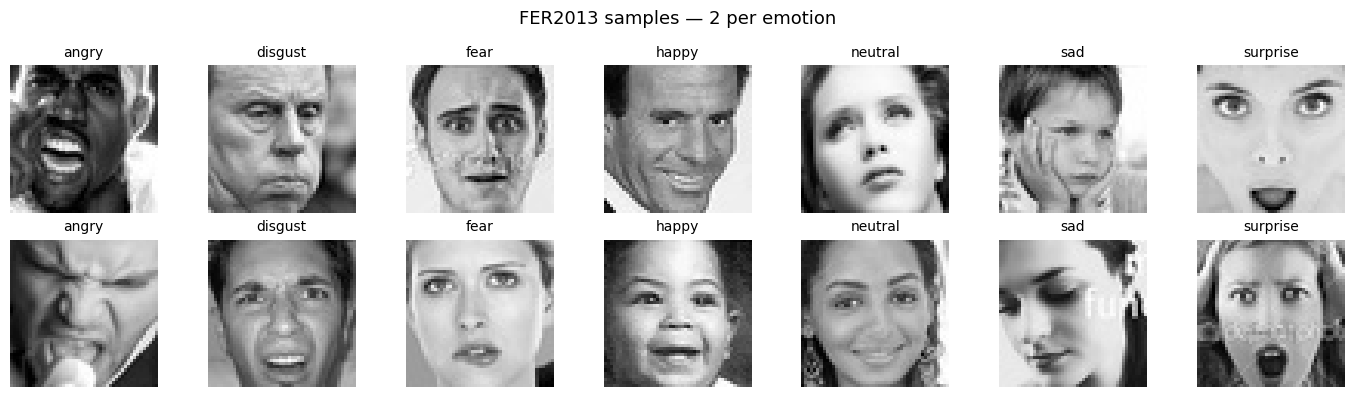

In [14]:
import random

import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

fig, axes = plt.subplots(2, 7, figsize=(14, 4))
for j, cls in enumerate(CLASS_NAMES):
    imgs = list((train_dir / cls).iterdir())
    chosen = random.sample(imgs, 2)
    for i, path in enumerate(chosen):
        axes[i, j].imshow(Image.open(path), cmap='gray')
        axes[i, j].set_title(cls, fontsize=10)
        axes[i, j].axis('off')
plt.suptitle('FER2013 samples — 2 per emotion', fontsize=13)
plt.tight_layout()
plt.show()

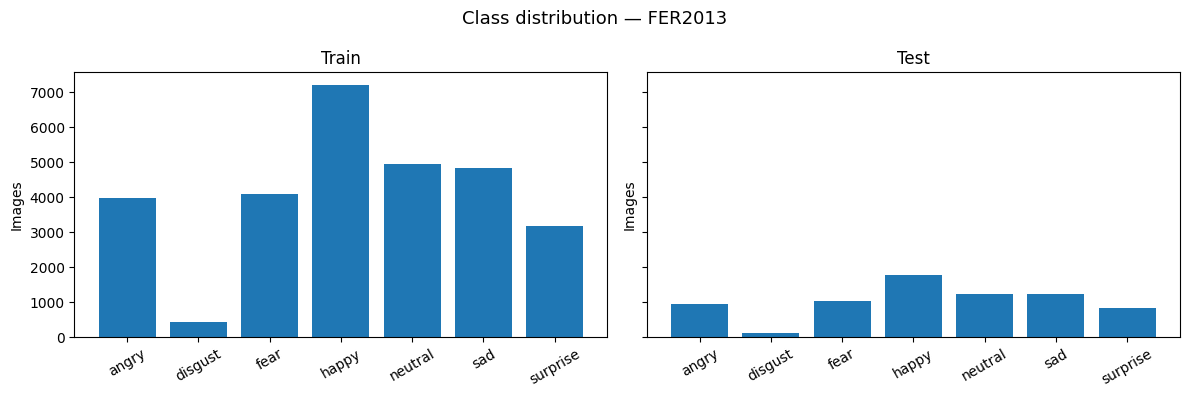

Train counts: {'angry': 3995, 'disgust': 436, 'fear': 4097, 'happy': 7215, 'neutral': 4965, 'sad': 4830, 'surprise': 3171}


In [15]:
import matplotlib.pyplot as plt

train_counts = {cls: len([p for p in (train_dir / cls).iterdir() if p.is_file()]) for cls in CLASS_NAMES}
test_counts = {cls: len([p for p in (test_dir / cls).iterdir() if p.is_file()]) for cls in CLASS_NAMES}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, counts, title in [(axes[0], train_counts, 'Train'), (axes[1], test_counts, 'Test')]:
    ax.bar(counts.keys(), counts.values())
    ax.set_title(title)
    ax.set_ylabel('Images')
    ax.tick_params(axis='x', rotation=30)
plt.suptitle('Class distribution — FER2013', fontsize=13)
plt.tight_layout()
plt.show()

print('Train counts:', train_counts)

### What to notice: class imbalance
FER2013 has an uneven number of images for each emotion. Some emotions have thousands of examples (like happy), while others have only a few hundred (like disgust). This means the model has more examples to learn from for certain emotions than others. Keep this imbalance in mind when looking at the model's performance, since overall accuracy may not show how well it recognizes every emotion.

## 3. Preprocessing and train/validation split

- **Validation:** A stratified 90/10 split of the official training set (seed 42), so each class keeps its proportion in both parts. The official test set remains untouched until final evaluation.
- **Preprocessing (no augmentation):** Resize(224, 224) ➡ Grayscale(num_output_channels=3) ➡ ToTensor() ➡ ImageNet normalization.
- FER2013 images are originally 48×48 grayscale images. They are resized to 224×224 and converted to three channels to match the input requirements of pretrained ResNet18.

- **Normalization:** ImageNet mean = [0.485, 0.456, 0.406] and standard deviation = [0.229, 0.224, 0.225], matching the preprocessing used for the pretrained model.

- The training and validation datasets use the same transformations because Experiment C does not use data augmentation.

In [16]:
import random
import numpy as np
import torch

from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# ImageNet normalization for pretrained ResNet18
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# No data augmentation in Experiment C
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels = 3),
    transforms.ToTensor(),
    transforms.Normalize(mean = imagenet_mean, std = imagenet_std)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels = 3),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

train_ds = datasets.ImageFolder(train_dir, transform=train_transform)
val_ds = datasets.ImageFolder(train_dir, transform=eval_transform)
test_ds = datasets.ImageFolder(test_dir, transform=eval_transform)

print('Classes (index order):', train_ds.classes)

# Same stratified 90/10 split as Experiment A
targets = train_ds.targets

train_idx, val_idx = train_test_split(
    range(len(train_ds)),
    test_size = 0.10,
    random_state = 42,
    stratify = targets
)

train_subset = Subset(train_ds, train_idx)
val_subset = Subset(val_ds, val_idx)

print(
    f'Train: {len(train_subset)} | '
    f'Val: {len(val_subset)} | '
    f'Test (held out): {len(test_ds)}'
    )

BATCH_SIZE = 64

train_loader = DataLoader(
    train_subset,
    batch_size = BATCH_SIZE,
    shuffle = True,
    num_workers = 2,
    pin_memory = torch.cuda.is_available()
)

val_loader = DataLoader(
    val_subset,
    batch_size = BATCH_SIZE,
    shuffle = False,
    num_workers = 2,
    pin_memory = torch.cuda.is_available()
)

test_loader = DataLoader(
    test_ds,
    batch_size = BATCH_SIZE,
    shuffle = False,
    num_workers = 2,
    pin_memory = torch.cuda.is_available()
)

# Check image dimensions
images, labels = next(iter(train_loader))

print('Batch:', images.shape, labels.shape)  # expect torch.Size([64, 3, 224, 224]) torch.Size([64])

Classes (index order): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Train: 25838 | Val: 2871 | Test (held out): 7178
Batch: torch.Size([64, 3, 224, 224]) torch.Size([64])


## 4. Model - pretrained ResNet18

This experiment uses a ResNet18 model pretrained on the ImageNet dataset. Instead of training a CNN from scratch, we start with pretrained weights and fine-tune the model for facial expression recognition.

- Input: 224x224 RGB images (converted from grayscale to 3 channels).
- Base model: ResNet18 with ImageNet pretrained weights.
- Output layer: The original 1000-class fully connected layer is replaced with a new fully connected layer with 7 outputs, one for each emotion.
- Training: The model is fine-tuned on the FER2013 training dataset to classify the seven facial expressions.

The same train/validation/test split is used as the baseline experiment so that the results can be compared fairly.

In [17]:
# Import ResNet18
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# Load ResNet18 with pretrained ImageNet weights
model = resnet18(weights = ResNet18_Weights.IMAGENET1K_V1)

# Replace the final fully connected layer for 7 emotion classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(CLASS_NAMES))

# Move model to GPU if available
model = model.to(device)

print("model: ", model)

# Test the model with a batch of 2 images
with torch.no_grad():
    sample = torch.randn(2, 3, 224, 224).to(device)
    output = model(sample)

print("Output shape:", output.shape)

assert output.shape == (2, 7)
print("ResNet18 model is working.")

model:  ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_run

## 5. Training

The pretrained ResNet18 model is fine-tuned using the FER2013 training dataset.

- Optimizer: Adam (learning rate = 0.001)
- Loss function: CrossEntropyLoss
- Epochs: 15
- Batch size: 64
- Model selection: The best checkpoint is saved based on validation accuracy.

Training and validation are performed using the same data split as Experiment A to ensure a fair comparison. The official test dataset remains untouched until final evaluation.

On a Colab T4 GPU, expect on the order of 10–20 minutes; do not run this on CPU if you can avoid it.

In [18]:
# --- Checkpoints ---
# Default: ./checkpoints (lost when the Colab runtime is recycled).
# To keep checkpoints on Google Drive instead,
# and set CHECKPOINT_DIR to the Drive path.

import os
from google.colab import drive

drive.mount('/content/drive')

CHECKPOINT_DIR = '/content/drive/MyDrive/emotion-detection/checkpoints/experiment_C'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print('Checkpoints will be saved to:', CHECKPOINT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoints will be saved to: /content/drive/MyDrive/emotion-detection/checkpoints/experiment_C


In [19]:
import json
import time
import torch
import torch.nn as nn
from tqdm import tqdm

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
NUM_EPOCHS = 15
best_path = os.path.join(CHECKPOINT_DIR, 'best_resnet18_pretrained.pth')


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, desc='train', leave=False):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate_loss_acc(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, desc='val', leave=False):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        running_loss += criterion(outputs, labels).item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0

print(f'Training for {NUM_EPOCHS} epochs (Adam lr=0.001, batch={BATCH_SIZE})...')
for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate_loss_acc(model, val_loader, criterion, device)
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                    'val_acc': best_val_acc}, best_path)
    print(f'Epoch {epoch:2d}/{NUM_EPOCHS} | train loss {train_loss:.4f} acc {train_acc:.4f} | '
          f'val loss {val_loss:.4f} acc {val_acc:.4f} | {time.time() - t0:.0f}s')

with open(os.path.join(CHECKPOINT_DIR, 'history_resnet18_pretrained.json'), 'w') as f:
    json.dump(history, f, indent=2)
print(f'\nBest val accuracy: {best_val_acc:.4f} - checkpoint saved to {best_path}')

Training for 15 epochs (Adam lr=0.001, batch=64)...


Epoch  1/15 | train loss 1.2099 acc 0.5447 | val loss 1.0999 acc 0.5747 | 95s


Epoch  2/15 | train loss 1.0131 acc 0.6192 | val loss 1.1166 acc 0.5716 | 106s


Epoch  3/15 | train loss 0.8975 acc 0.6634 | val loss 1.0342 acc 0.6245 | 99s


Epoch  4/15 | train loss 0.7749 acc 0.7126 | val loss 1.0084 acc 0.6315 | 101s


Epoch  5/15 | train loss 0.6220 acc 0.7718 | val loss 1.0951 acc 0.6294 | 105s


... (6 outputs left out)

Epoch 12/15 | train loss 0.0965 acc 0.9680 | val loss 2.0358 acc 0.6179 | 97s


Epoch 13/15 | train loss 0.0876 acc 0.9709 | val loss 2.0696 acc 0.6193 | 99s


Epoch 14/15 | train loss 0.0655 acc 0.9773 | val loss 2.1603 acc 0.6252 | 99s


Epoch 15/15 | train loss 0.0804 acc 0.9728 | val loss 2.0496 acc 0.6165 | 98s

Best val accuracy: 0.6315 — checkpoint saved to /content/drive/MyDrive/emotion-detection/checkpoints/experiment_C/best_resnet18_pretrained.pth


## 6. Evaluation

Load the best pretrained ResNet18 checkpoint selected during training and evaluate its performance on the validation set. Report per-class precision, recall, and F1-score because overall accuracy alone may hide the effects of class imbalance.

Also, plot the normalized confusion matrix and training curves to examine how well the model recognizes each emotion and identify potential overfitting.

The official FER2013 test set will remain untouched until the final comparison of all four experiments.

In [22]:
import torch
import os

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "best_resnet18_pretrained.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Load only the model weights
model.load_state_dict(checkpoint["model_state_dict"])

# Set model to evaluation mode
model.eval()

print("Best pretrained ResNet18 loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Validation accuracy:", checkpoint["val_acc"])

Best pretrained ResNet18 loaded successfully!
Best epoch: 4
Validation accuracy: 0.6314872866597004


In [27]:
from sklearn.metrics import classification_report

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in tqdm(val_loader, desc='eval'):
        outputs = model(images.to(device))
        all_preds.extend(outputs.argmax(1).cpu().tolist())
        all_labels.extend(labels.tolist())

print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES, digits=4))

eval: 100%|██████████| 45/45 [00:11<00:00,  3.86it/s]


              precision    recall  f1-score   support

       angry     0.5037    0.6792    0.5784       399
     disgust     0.7368    0.3182    0.4444        44
        fear     0.5256    0.2756    0.3616       410
       happy     0.8708    0.8213    0.8453       722
     neutral     0.5542    0.6593    0.6022       496
         sad     0.5087    0.4824    0.4952       483
    surprise     0.7081    0.8265    0.7627       317

    accuracy                         0.6315      2871
   macro avg     0.6297    0.5804    0.5843      2871
weighted avg     0.6349    0.6315    0.6230      2871



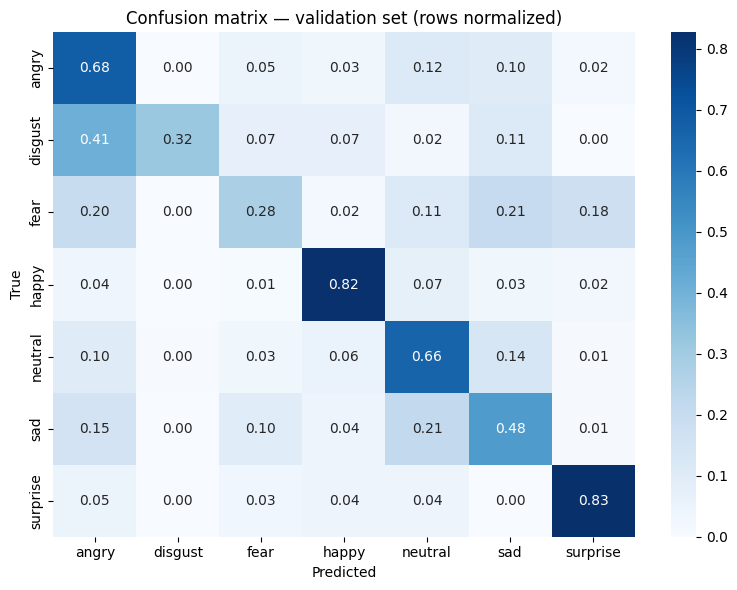

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_preds, normalize='true')
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion matrix — validation set (rows normalized)')
plt.tight_layout()
plt.show()

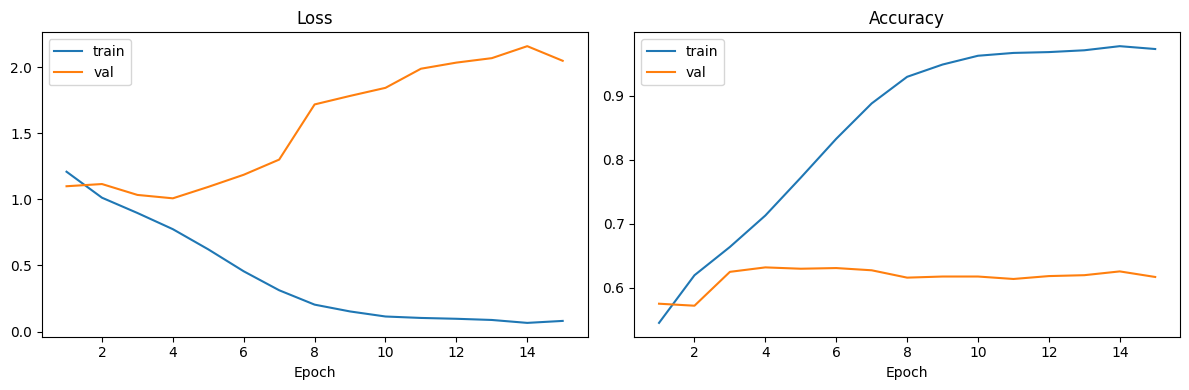

In [25]:
import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history['train_loss'], label='train')
axes[0].plot(epochs, history['val_loss'], label='val')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[1].plot(epochs, history['train_acc'], label='train')
axes[1].plot(epochs, history['val_acc'], label='val')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()
plt.tight_layout()
plt.show()

## What to record for the report

- **Best validation accuracy:** 63.15%, achieved at Epoch 4.
- **Per-class precision / recall / F1** Happy performed best with an F1-score of 84.53%, followed by surprise at 76.27%. Fear performed worst at 36.16%.
- **The confusion matrix figure:** Happy and surprise were recognized most accurately (82% and 83%, respectively). Disgust was frequently misclassified as angry (41%). Fear was commonly confused with sad (21%), angry (20%), and surprise (18%). Sad was also frequently confused with neutral (21%).
- **The training curves:** The model showed signs of overfitting. Training accuracy increased to approximately 97%, while validation accuracy peaked at 63.15% at Epoch 4 and then plateaued. Validation loss increased as training continued. This suggests that the model learned the training data well but did not generalize as effectively to unseen images. These results motivate the use of data augmentation in Experiment D to investigate whether it can improve generalization.
- **Saved files:** Keep best_resnet18_pretrained.pth and `history_resnet18_pretrained.json` in the Experiment C `checkpoint` folder. Also save the normalized confusion matrix and training curves for the final report.

## Notes for the next experiments

**D (ResNet18 + augmentation):** C with the augmentation transforms from B.
+ Start with the Experiment C ResNet18 model and add the data augmentation techniques used in Experiment B.
+ Apply augmentation only to the training data. Keep validation and test transformations unchanged.
+ Compare Experiment D against Experiment C to investigate whether data augmentation improves validation performance and reduces overfitting.

**Robustness tests (Nov 23 milestone):** evaluate every trained model on distorted copies of the *test* set — dark (brightness ×0.5), bright (×1.5), rotation ±15°/±30°, eye occlusion, mouth occlusion — using the same transforms for all four models.